# Factor-Based Portfolio Construction & Backtesting

---

## 1. Introduction

Factor investing is one of the most well-established paradigms in quantitative finance. The central idea is that **systematic risk premia** — persistent return differentials that compensate investors for bearing specific types of risk — can be captured through disciplined, rules-based portfolio construction.

### The Fama-French Framework

Eugene Fama and Kenneth French (1993) proposed that stock returns are driven by exposure to a small number of **common factors**:

$$R_i - R_f = \alpha_i + \beta_{i,\text{MKT}}(R_m - R_f) + \beta_{i,\text{SMB}} \cdot \text{SMB} + \beta_{i,\text{HML}} \cdot \text{HML} + \varepsilon_i$$

where:
- $R_i - R_f$ is the excess return of asset $i$
- $R_m - R_f$ is the market risk premium
- $\text{SMB}$ (Small Minus Big) captures the **size** premium
- $\text{HML}$ (High Minus Low) captures the **value** premium

Subsequent research has extended this framework to include **momentum** (Carhart, 1997), **profitability** and **investment** (Fama-French five-factor model, 2015), and **low volatility** (Baker, Bradley & Wurgler, 2011).

### This Notebook

This notebook performs the following steps:
1. Download **real market data** for 30 U.S. equities across 7 sectors using `yfinance`
2. Construct four well-known factors: **Momentum**, **Value**, **Quality**, and **Low Volatility**
3. Build quintile portfolios sorted on a composite factor score
4. Evaluate performance with professional risk-return analytics
5. Run **Fama-MacBeth** cross-sectional regressions to estimate factor premia
6. Analyze factor decay, turnover, and transaction costs
7. Perform out-of-sample validation and rolling analysis

### Stock Universe

| Sector | Tickers |
|:-------|:--------|
| **Technology** | AAPL, MSFT, GOOGL, AMZN, META, NVDA |
| **Financials** | JPM, BAC, GS, WFC, MS |
| **Healthcare** | JNJ, UNH, PFE, MRK, ABT |
| **Consumer Staples** | PG, KO, PEP, WMT, COST |
| **Energy** | XOM, CVX, COP |
| **Industrials** | CAT, BA, HON, GE |
| **Utilities/REITs** | NEE, DUK, AMT, SPG |

> **Note:** This notebook uses real market data via `yfinance`. If the download fails (e.g., no internet), it falls back to synthetic data automatically.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
import statsmodels.api as sm
import warnings

warnings.filterwarnings('ignore')

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        plt.style.use('ggplot')

COLORS = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B',
          '#44BBA4', '#E94F37', '#393E41', '#8D6A9F', '#5FAD56']

plt.rcParams.update({
    'figure.dpi': 100,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'font.size': 11,
})

print("All imports successful. Ready to go.")

All imports successful. Ready to go.


In [2]:
RISK_FREE_RATE = 0.02
TRADING_DAYS_PER_YEAR = 252
START_DATE = '2019-01-01'
END_DATE   = '2024-01-01'

SECTOR_TICKERS = {
    'Technology':       ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA'],
    'Financials':       ['JPM', 'BAC', 'GS', 'WFC', 'MS'],
    'Healthcare':       ['JNJ', 'UNH', 'PFE', 'MRK', 'ABT'],
    'Consumer Staples': ['PG', 'KO', 'PEP', 'WMT', 'COST'],
    'Energy':           ['XOM', 'CVX', 'COP'],
    'Industrials':      ['CAT', 'BA', 'HON', 'GE'],
    'Utilities/REITs':  ['NEE', 'DUK', 'AMT', 'SPG'],
}

ALL_TICKERS = [t for ts in SECTOR_TICKERS.values() for t in ts]
TICKER_SECTOR = {t: s for s, ts in SECTOR_TICKERS.items() for t in ts}

print(f"Universe : {len(ALL_TICKERS)} stocks across {len(SECTOR_TICKERS)} sectors")
print(f"Period   : {START_DATE} to {END_DATE}")
print(f"Rf       : {RISK_FREE_RATE:.1%} annualized")
print(f"Tickers  : {', '.join(ALL_TICKERS)}")

Universe : 32 stocks across 7 sectors
Period   : 2019-01-01 to 2024-01-01
Rf       : 2.0% annualized
Tickers  : AAPL, MSFT, GOOGL, AMZN, META, NVDA, JPM, BAC, GS, WFC, MS, JNJ, UNH, PFE, MRK, ABT, PG, KO, PEP, WMT, COST, XOM, CVX, COP, CAT, BA, HON, GE, NEE, DUK, AMT, SPG


---
## 2. Market Data

The following section downloads daily adjusted closing prices for the 30-stock universe from **Yahoo Finance** using the `yfinance` library. The data covers January 2019 through December 2023, providing approximately 5 years of daily observations.

If the download fails (e.g., no internet connection or API changes), the notebook **automatically falls back** to synthetic data generated via correlated geometric Brownian motion (GBM) with realistic factor structure, ensuring the notebook always runs.

### Why Real Data?

Using real market data makes it possible to:
- Observe genuine factor behavior (momentum crashes in 2020, value recovery in 2022)
- Test on actual correlation structures and regime changes (COVID-19, rate hikes)
- Validate whether the analytical tools produce sensible results on messy, real-world data


In [3]:
USE_REAL_DATA = False

try:
    import yfinance as yf
    print("Downloading market data from Yahoo Finance...")
    data = yf.download(ALL_TICKERS, start=START_DATE, end=END_DATE, progress=True, auto_adjust=True)

    if isinstance(data.columns, pd.MultiIndex):
        prices = data['Close'].copy()
    else:
        prices = data.copy()

    prices = prices.dropna(axis=1, how='all')
    prices = prices.dropna(how='all')
    prices = prices.ffill()

    if prices.shape[1] >= 15 and len(prices) >= 500:
        USE_REAL_DATA = True
        stock_names = list(prices.columns)
        sector_labels = [TICKER_SECTOR.get(t, 'Unknown') for t in stock_names]
        N_STOCKS = len(stock_names)
        print(f"\n✅ Successfully downloaded {N_STOCKS} stocks, {len(prices)} trading days")
        print(f"   Date range: {prices.index[0].strftime('%Y-%m-%d')} to {prices.index[-1].strftime('%Y-%m-%d')}")
        failed = set(ALL_TICKERS) - set(stock_names)
        if failed:
            print(f"   ⚠️ Failed tickers (excluded): {', '.join(failed)}")
    else:
        raise ValueError(f"Insufficient data: {prices.shape[1]} stocks, {len(prices)} days")

except Exception as e:
    print(f"⚠️  Could not download market data: {e}")
    print("    Falling back to synthetic data generation...\n")
    USE_REAL_DATA = False

if not USE_REAL_DATA:
    np.random.seed(42)
    N_STOCKS = 30

    SECTORS_SYNTH = {
        'Technology': 6, 'Financials': 5, 'Healthcare': 5,
        'Consumer Staples': 5, 'Energy': 3, 'Industrials': 4,
        'Utilities/REITs': 2,
    }

    sector_labels = []
    for sec, cnt in SECTORS_SYNTH.items():
        sector_labels.extend([sec] * cnt)

    stock_names = ALL_TICKERS[:N_STOCKS] if len(ALL_TICKERS) >= N_STOCKS else \
                  [f'STK_{i:03d}' for i in range(N_STOCKS)]

    dates = pd.bdate_range(start=START_DATE, end=END_DATE)
    T = len(dates)
    dt = 1 / TRADING_DAYS_PER_YEAR

    annual_drifts = np.random.uniform(0.02, 0.15, N_STOCKS)
    annual_vols   = np.random.uniform(0.15, 0.50, N_STOCKS)

    beta_mkt = np.random.uniform(0.6, 1.4, N_STOCKS)
    beta_sec = np.random.uniform(0.1, 0.4, N_STOCKS)
    idio_weight = np.sqrt(np.clip(1 - beta_mkt**2 - beta_sec**2, 0.01, None))

    f_mkt = np.random.randn(T)
    unique_sectors = list(SECTORS_SYNTH.keys())
    sector_factor_map = {s: np.random.randn(T) for s in unique_sectors}

    noise = np.zeros((N_STOCKS, T))
    for i in range(N_STOCKS):
        sec = sector_labels[i]
        noise[i] = (beta_mkt[i] * f_mkt
                    + beta_sec[i] * sector_factor_map[sec]
                    + idio_weight[i] * np.random.randn(T))

    log_returns = (annual_drifts[:, None] - 0.5 * annual_vols[:, None]**2) * dt \
                  + annual_vols[:, None] * np.sqrt(dt) * noise

    initial_prices = np.random.uniform(20, 200, N_STOCKS)
    log_prices = np.log(initial_prices[:, None]) + np.cumsum(log_returns, axis=1)
    prices_array = np.exp(log_prices)

    prices = pd.DataFrame(prices_array.T, index=dates, columns=stock_names)

    print(f"✅ Synthetic data generated: {N_STOCKS} stocks, {len(prices)} trading days")

print(f"\n{'='*60}")
print(f"Data source : {'REAL (Yahoo Finance)' if USE_REAL_DATA else 'SYNTHETIC (GBM)'}")
print(f"Stocks      : {N_STOCKS}")
print(f"Trading days: {len(prices)}")
print(f"{'='*60}")

[*********************100%***********************]  32 of 32 completed


✅ Successfully downloaded 32 stocks, 1258 trading days
   Date range: 2019-01-02 to 2023-12-29

Data source : REAL (Yahoo Finance)
Stocks      : 32
Trading days: 1258


In [4]:
monthly_prices = prices.resample('ME').last()
monthly_returns = monthly_prices.pct_change().dropna()

summary = pd.DataFrame({
    'Ann. Return': monthly_returns.mean() * 12,
    'Ann. Vol':    monthly_returns.std() * np.sqrt(12),
    'Sharpe':      (monthly_returns.mean() * 12 - RISK_FREE_RATE) / (monthly_returns.std() * np.sqrt(12)),
    'Skewness':    monthly_returns.skew(),
    'Kurtosis':    monthly_returns.kurtosis(),
    'Sector':      sector_labels[:len(monthly_returns.columns)],
})

print("Cross-Sectional Summary Statistics (Annualized)")
print("=" * 60)
for col in ['Ann. Return', 'Ann. Vol', 'Sharpe']:
    print(f"  {col:15s}  mean={summary[col].mean():.3f}   "
          f"std={summary[col].std():.3f}   "
          f"min={summary[col].min():.3f}   max={summary[col].max():.3f}")

print(f"\nSector Average Returns:")
print(summary.groupby('Sector')['Ann. Return'].mean().sort_values(ascending=False).to_string())

Cross-Sectional Summary Statistics (Annualized)
  Ann. Return      mean=0.177   std=0.119   min=0.005   max=0.668
  Ann. Vol         mean=0.291   std=0.094   min=0.161   max=0.498
  Sharpe           mean=0.545   std=0.315   min=-0.054   max=1.303

Sector Average Returns:
Sector
Technology          0.326758
Energy              0.190197
Financials          0.166313
Industrials         0.160498
Consumer Staples    0.149823
Healthcare          0.103663
Utilities/REITs     0.100973


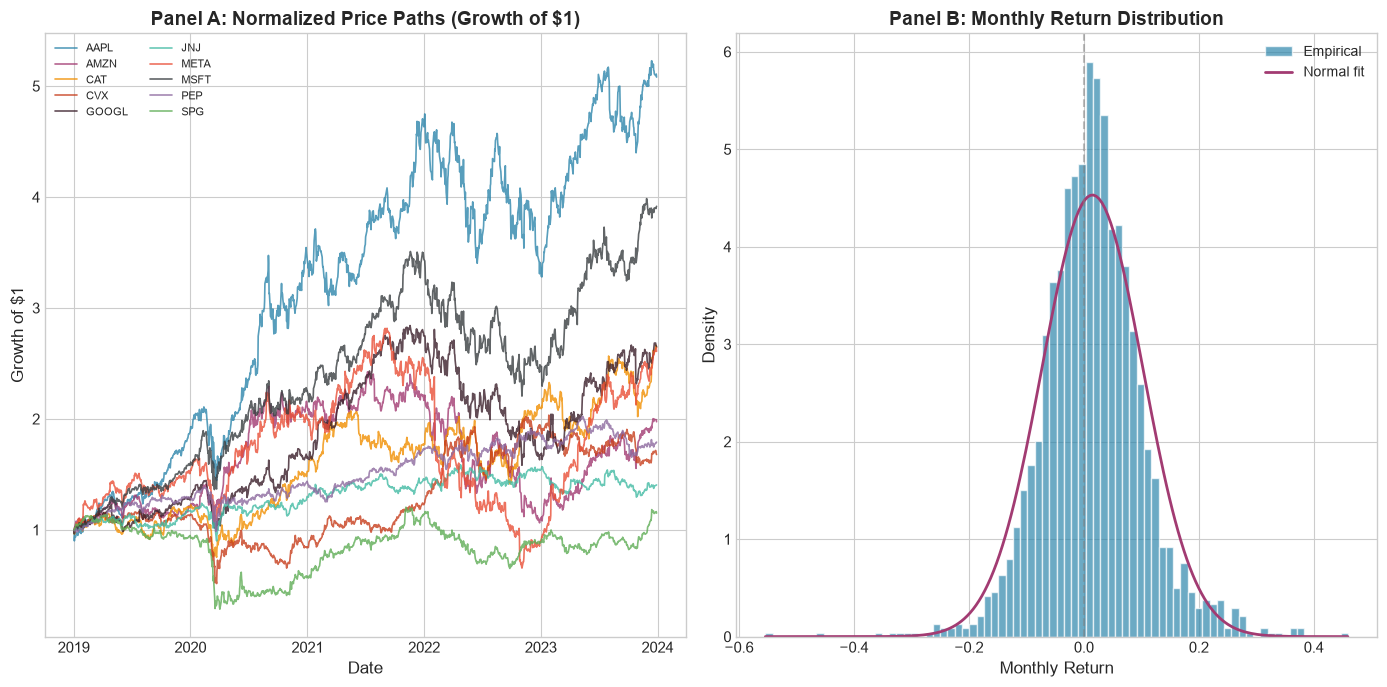

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

ax = axes[0]
sample_stocks = stock_names[::max(1, len(stock_names)//10)][:10]
for i, stk in enumerate(sample_stocks):
    normalized = prices[stk] / prices[stk].iloc[0]
    ax.plot(prices.index, normalized, color=COLORS[i % len(COLORS)],
            alpha=0.8, linewidth=1.2, label=stk)
ax.set_title('Panel A: Normalized Price Paths (Growth of $1)', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Growth of $1')
ax.legend(fontsize=8, ncol=2, loc='upper left')

ax = axes[1]
all_monthly = monthly_returns.values.flatten()
all_monthly = all_monthly[~np.isnan(all_monthly)]
ax.hist(all_monthly, bins=80, color=COLORS[0], alpha=0.7, edgecolor='white',
        density=True, label='Empirical')
x_range = np.linspace(all_monthly.min(), all_monthly.max(), 200)
ax.plot(x_range, stats.norm.pdf(x_range, all_monthly.mean(), all_monthly.std()),
        color=COLORS[1], linewidth=2, label='Normal fit')
ax.set_title('Panel B: Monthly Return Distribution', fontweight='bold')
ax.set_xlabel('Monthly Return')
ax.set_ylabel('Density')
ax.legend()
ax.axvline(0, color='grey', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 3. Factor Construction

The analysis constructs **four** well-known equity factors. Each factor is computed as a cross-sectional **z-score** (rank-standardized) each month, so that they are directly comparable and can be combined into a composite signal.

### 3a. Momentum Factor (12-1 month)

The momentum signal follows the Jegadeesh & Titman (1993) specification:

$$\text{MOM}_{i,t} = \frac{P_{i,t-1}}{P_{i,t-12}} - 1$$

The signal skips the most recent month to avoid the well-documented **short-term reversal** effect. Stocks with high past returns are expected to continue outperforming.


In [6]:
mom_raw = monthly_prices.shift(1) / monthly_prices.shift(12) - 1

def cross_sectional_zscore(df):
    '''Rank-based z-score: rank -> uniform -> inverse normal.'''
    ranked = df.rank(axis=1, pct=True)
    ranked = ranked.clip(0.001, 0.999)
    return pd.DataFrame(
        stats.norm.ppf(ranked),
        index=df.index, columns=df.columns
    )

mom_zscore = cross_sectional_zscore(mom_raw)

print("Momentum Factor — Sample (last 3 months, first 8 stocks):")
mom_zscore.iloc[-3:, :8].round(2)

Momentum Factor — Sample (last 3 months, first 8 stocks):


Ticker,AAPL,ABT,AMT,AMZN,BA,BAC,CAT,COP
Date,,,,,,,,
2023-10-31,0.40,-0.08,-1.15,0.78,1.01,-1.32,0.89,-0.16
2023-11-30,0.89,-0.40,-0.78,1.32,0.67,-1.32,0.08,0.32
2023-12-31,0.89,-0.32,-0.16,1.32,0.67,-0.58,0.24,-0.08


### 3b. Value Factor (Price-Based Proxy)

In the absence of granular fundamental data, the analysis uses the **inverse of the trailing 12-month return** as a contrarian value proxy:

$$\text{VAL}_{i,t} = -\left(\frac{P_{i,t}}{P_{i,t-12}} - 1\right)$$

This captures the idea that stocks which have underperformed over the past year may be undervalued — the classic **mean-reversion** or **value** hypothesis. In practice, production implementations would use book-to-market ($B/M$), earnings yield ($E/P$), or cash-flow yield ($CF/P$).


In [7]:
trailing_12m = monthly_prices / monthly_prices.shift(12) - 1
val_raw = -trailing_12m

val_zscore = cross_sectional_zscore(val_raw)

print("Value Factor — Sample (last 3 months, first 8 stocks):")
val_zscore.iloc[-3:, :8].round(2)

Value Factor — Sample (last 3 months, first 8 stocks):


Ticker,AAPL,ABT,AMT,AMZN,BA,BAC,CAT,COP
Date,,,,,,,,
2023-10-31,-0.40,0.32,1.01,-0.78,-0.89,1.86,-0.16,0.16
2023-11-30,-0.67,0.00,0.16,-1.15,-0.78,1.32,-0.32,0.08
2023-12-31,-0.78,0.24,0.08,-1.15,-0.58,0.16,-0.32,0.32


### 3c. Quality Factor (Return Stability)

The analysis proxies **quality** as the inverse of trailing 12-month return volatility:

$$\text{QUAL}_{i,t} = \frac{1}{\sigma_{i}^{(12m)}}$$

where $\sigma_{i}^{(12m)}$ is the standard deviation of the most recent 12 monthly returns. Stocks with more **stable** (less volatile) returns are considered higher quality.


In [8]:
qual_raw = 1.0 / monthly_returns.rolling(12).std()

qual_zscore = cross_sectional_zscore(qual_raw)

print("Quality Factor — Sample (last 3 months, first 8 stocks):")
qual_zscore.iloc[-3:, :8].round(2)

Quality Factor — Sample (last 3 months, first 8 stocks):


Ticker,AAPL,ABT,AMT,AMZN,BA,BAC,CAT,COP
Date,,,,,,,,
2023-10-31,-0.32,0.32,-0.16,-1.15,-1.53,-0.58,-0.89,0.08
2023-11-30,-0.40,0.16,-0.49,-1.15,-1.32,-1.01,-0.89,0.08
2023-12-31,0.16,-0.08,-0.49,-0.58,-1.32,-0.89,-1.53,0.00


### 3d. Low Volatility Factor

The **low-volatility anomaly** (Baker, Bradley & Wurgler, 2011) shows that low-risk stocks earn higher risk-adjusted returns than predicted by the CAPM. The measurement uses 60-day realized volatility:

$$\text{LVOL}_{i,t} = \frac{1}{\hat{\sigma}_{i,t}^{(60d)}}$$

where $\hat{\sigma}_{i,t}^{(60d)} = \sqrt{\frac{252}{60} \sum_{k=0}^{59} r_{i,t-k}^2}$ is the annualized 60-trading-day realized volatility.


In [9]:
daily_returns = prices.pct_change().dropna()
daily_vol_60 = daily_returns.rolling(60).std() * np.sqrt(252)

monthly_vol = daily_vol_60.resample('ME').last()
monthly_vol = monthly_vol.reindex(monthly_returns.index)

lvol_raw = 1.0 / monthly_vol

lvol_zscore = cross_sectional_zscore(lvol_raw)

print("Low Volatility Factor — Sample (last 3 months, first 8 stocks):")
lvol_zscore.iloc[-3:, :8].round(2)

Low Volatility Factor — Sample (last 3 months, first 8 stocks):


Ticker,AAPL,ABT,AMT,AMZN,BA,BAC,CAT,COP
Date,,,,,,,,
2023-10-31,0.40,0.32,-1.15,-1.32,-0.24,-0.08,-0.67,-0.40
2023-11-30,0.58,0.40,-1.15,-1.32,-0.24,-0.49,-0.58,-0.67
2023-12-31,1.32,0.49,-0.89,-0.58,0.00,-0.67,-1.01,-0.16


### Composite Factor Score

The four individual factor z-scores combine into a single **composite score** using equal weights:

$$\text{COMPOSITE}_{i,t} = \frac{1}{4}\left(z_{i,t}^{\text{MOM}} + z_{i,t}^{\text{VAL}} + z_{i,t}^{\text{QUAL}} + z_{i,t}^{\text{LVOL}}\right)$$

A higher composite score indicates a stock that is simultaneously high-momentum, cheap, high-quality, and low-volatility — the "ideal" multi-factor stock.


In [10]:
common_idx = mom_zscore.dropna(how='all').index.intersection(
    val_zscore.dropna(how='all').index).intersection(
    qual_zscore.dropna(how='all').index).intersection(
    lvol_zscore.dropna(how='all').index)

factor_dict = {
    'Momentum': mom_zscore.loc[common_idx],
    'Value':    val_zscore.loc[common_idx],
    'Quality':  qual_zscore.loc[common_idx],
    'LowVol':   lvol_zscore.loc[common_idx],
}

composite = (factor_dict['Momentum'] + factor_dict['Value']
             + factor_dict['Quality'] + factor_dict['LowVol']) / 4.0

print(f"Composite score available for {len(common_idx)} months "
      f"({common_idx[0].strftime('%Y-%m')} to {common_idx[-1].strftime('%Y-%m')})")
print(f"\nComposite Score — Descriptive Stats (pooled):")
print(composite.stack().describe().round(3))

Composite score available for 48 months (2020-01 to 2023-12)

Composite Score — Descriptive Stats (pooled):
count    1536.000
mean        0.097
std         0.476
min        -1.180
25%        -0.236
50%         0.065
75%         0.403
max         1.934
dtype: float64


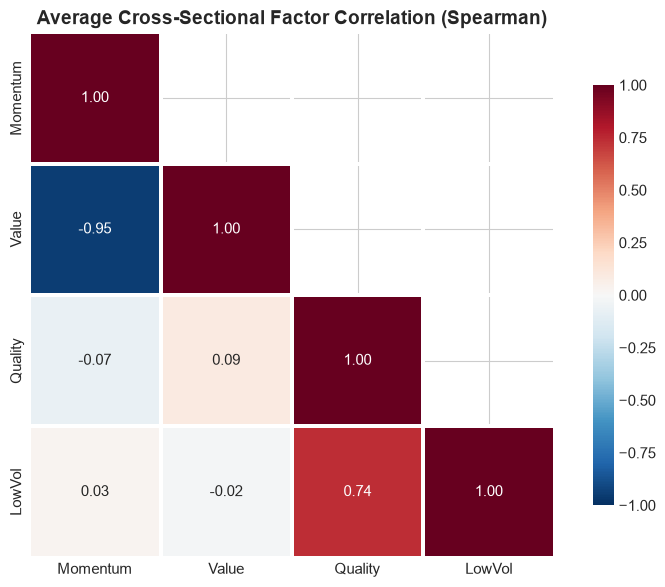

In [11]:
factor_names = list(factor_dict.keys())
corr_matrices = []
for t in common_idx:
    month_data = pd.DataFrame({f: factor_dict[f].loc[t] for f in factor_names}).dropna()
    if len(month_data) > 10:
        corr_matrices.append(month_data.corr(method='spearman'))

avg_corr = pd.concat(corr_matrices).groupby(level=0).mean()
avg_corr = avg_corr.reindex(index=factor_names, columns=factor_names)

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(avg_corr, dtype=bool), k=1)
sns.heatmap(avg_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, mask=mask, square=True,
            linewidths=1.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Average Cross-Sectional Factor Correlation (Spearman)', fontweight='bold')
plt.tight_layout()
plt.show()

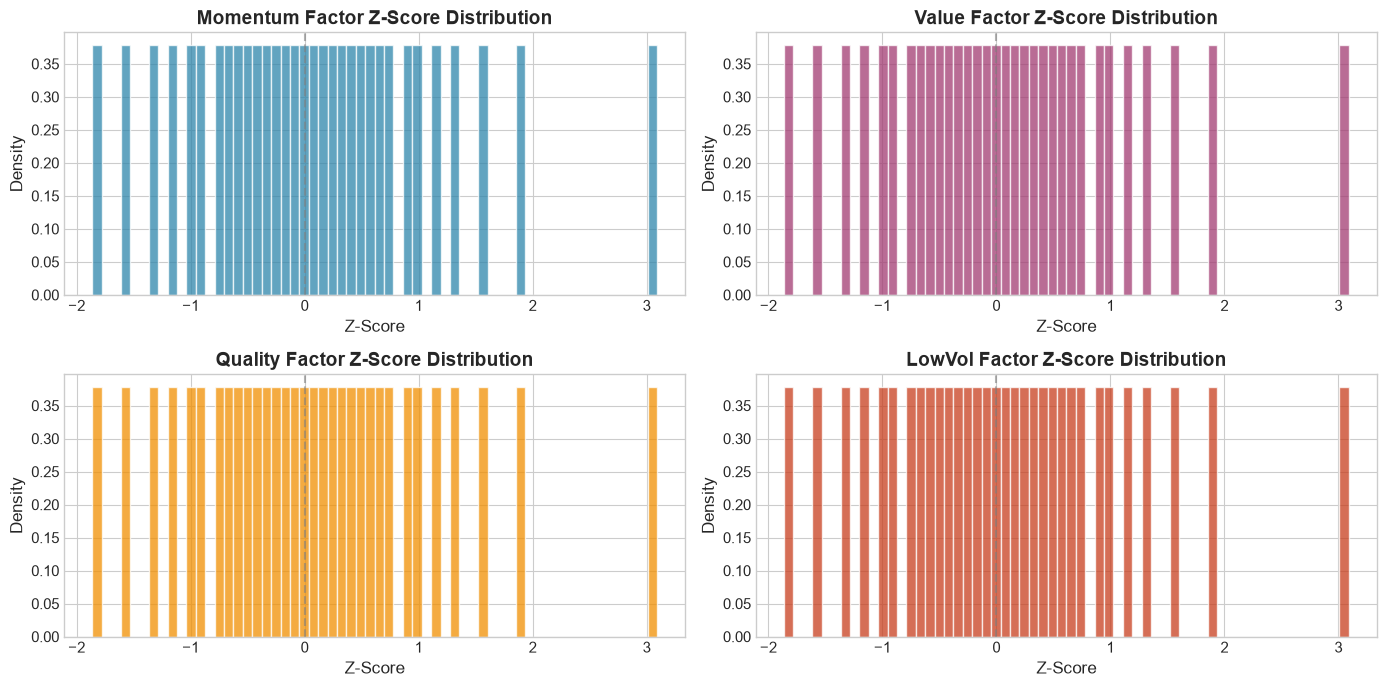

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for idx, (fname, fdata) in enumerate(factor_dict.items()):
    ax = axes[idx // 2, idx % 2]
    pooled = fdata.values.flatten()
    pooled = pooled[~np.isnan(pooled)]
    ax.hist(pooled, bins=60, color=COLORS[idx], alpha=0.75, edgecolor='white', density=True)
    ax.set_title(f'{fname} Factor Z-Score Distribution', fontweight='bold')
    ax.set_xlabel('Z-Score')
    ax.set_ylabel('Density')
    ax.axvline(0, color='grey', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## 4. Quintile Portfolio Construction

Each month, stocks are sorted into **quintile portfolios** based on the composite factor score:

| Quintile | Description |
|:--------:|:------------|
| **Q1** | Top 20% — highest composite score (best factor exposure) |
| **Q2** | 2nd quintile |
| **Q3** | Middle quintile |
| **Q4** | 4th quintile |
| **Q5** | Bottom 20% — lowest composite score (worst factor exposure) |

The **long-short** portfolio is $Q1 - Q5$, which isolates the pure factor return.


In [13]:
def assign_quintiles(row):
    '''Assign 1 (best) to 5 (worst) based on composite score.'''
    valid = row.dropna()
    if len(valid) < 5:
        return pd.Series(np.nan, index=row.index)
    quintile = pd.qcut(valid, 5, labels=[5, 4, 3, 2, 1])
    return quintile.reindex(row.index)

quintile_assignments = composite.apply(assign_quintiles, axis=1)

total_counts = quintile_assignments.stack().value_counts().sort_index()
print("Total stock-month observations per quintile:")
print(total_counts.to_string())

Total stock-month observations per quintile:
5    336
4    288
3    288
2    288
1    336


In [14]:
ret_aligned = monthly_returns.loc[common_idx]

quintile_returns = {}
for q in range(1, 6):
    mask = (quintile_assignments == q).astype(float)
    mask = mask.replace(0, np.nan)
    mask_shifted = mask.shift(1)
    n_stocks = mask_shifted.count(axis=1)
    qr = (ret_aligned * mask_shifted).sum(axis=1) / mask_shifted.sum(axis=1)
    quintile_returns[f'Q{q}'] = qr

quintile_df = pd.DataFrame(quintile_returns).dropna()

quintile_df['L/S (Q1-Q5)'] = quintile_df['Q1'] - quintile_df['Q5']

quintile_df['Benchmark'] = ret_aligned.loc[quintile_df.index].mean(axis=1)

print(f"Quintile returns computed for {len(quintile_df)} months")
print(f"\nMean Monthly Returns:")
print((quintile_df.mean() * 100).round(3).to_string() + '  (% per month)')

Quintile returns computed for 47 months

Mean Monthly Returns:
Q1             0.618
Q2             1.243
Q3             0.999
Q4             1.326
Q5             2.888
L/S (Q1-Q5)   -2.271
Benchmark      1.436  (% per month)


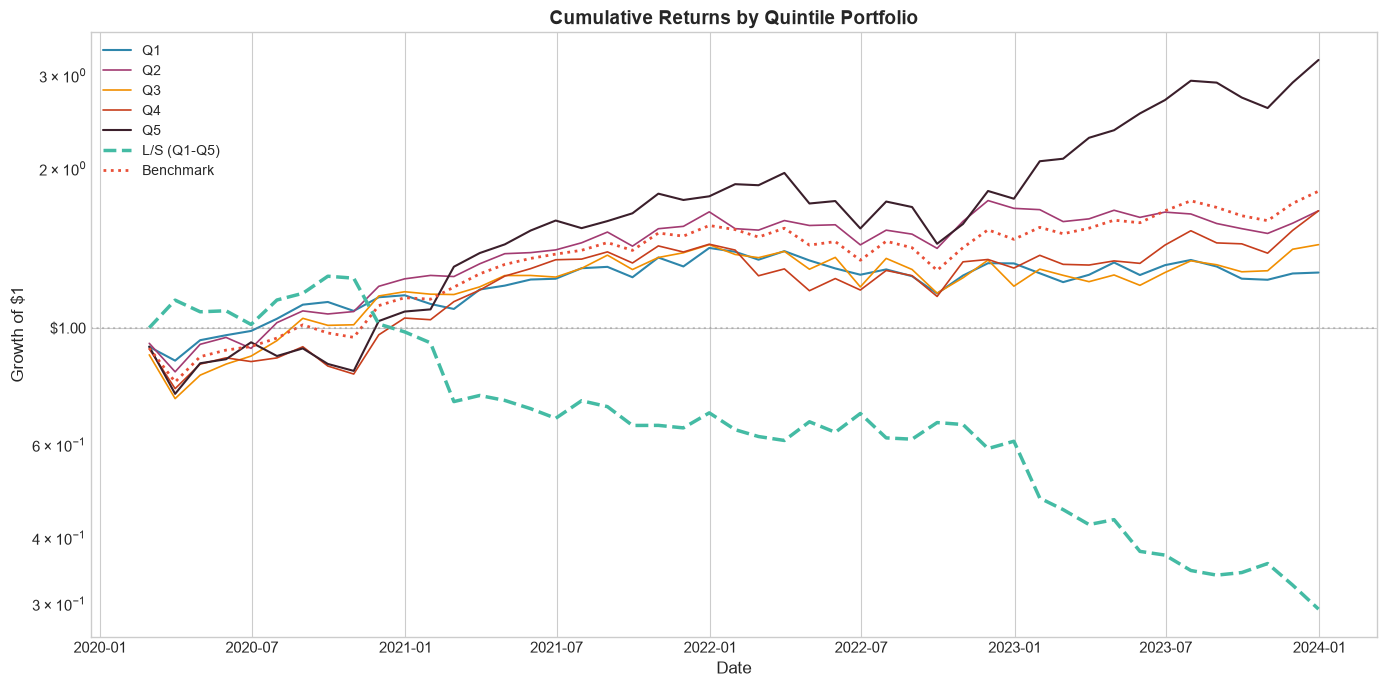

In [15]:
cumulative = (1 + quintile_df).cumprod()

fig, ax = plt.subplots(figsize=(14, 7))
plot_cols = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'L/S (Q1-Q5)', 'Benchmark']
line_styles = ['-', '-', '-', '-', '-', '--', ':']
line_widths = [1.5, 1.2, 1.2, 1.2, 1.5, 2.5, 2.0]

for i, col in enumerate(plot_cols):
    ax.plot(cumulative.index, cumulative[col],
            color=COLORS[i % len(COLORS)],
            linestyle=line_styles[i],
            linewidth=line_widths[i],
            label=col)

ax.set_title('Cumulative Returns by Quintile Portfolio', fontweight='bold', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Growth of $1')
ax.legend(loc='upper left', framealpha=0.9, fontsize=10)
ax.axhline(1, color='grey', linestyle=':', alpha=0.4)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'${y:.2f}'))

plt.tight_layout()
plt.show()

---
## 5. Performance Analytics

A comprehensive set of risk-return metrics is computed for each quintile portfolio:

| Metric | Formula |
|:-------|:--------|
| Annualized Return | $\bar{r} \times 12$ |
| Annualized Volatility | $\sigma \times \sqrt{12}$ |
| Sharpe Ratio | $\frac{\bar{r} \times 12 - R_f}{\sigma \times \sqrt{12}}$ |
| Sortino Ratio | $\frac{\bar{r} \times 12 - R_f}{\sigma_d \times \sqrt{12}}$ where $\sigma_d$ uses only negative returns |
| Maximum Drawdown | $\max_t \left(\frac{\text{Peak}_t - \text{Value}_t}{\text{Peak}_t}\right)$ |
| Calmar Ratio | $\frac{\text{Ann. Return}}{\lvert\text{Max Drawdown}\rvert}$ |


In [16]:
def compute_metrics(returns, rf=RISK_FREE_RATE):
    '''Compute a full suite of performance analytics from a monthly return series.'''
    ann_ret = returns.mean() * 12
    ann_vol = returns.std() * np.sqrt(12)
    sharpe  = (ann_ret - rf) / ann_vol if ann_vol > 0 else np.nan

    downside = returns[returns < 0].std() * np.sqrt(12)
    sortino  = (ann_ret - rf) / downside if downside > 0 else np.nan

    cum = (1 + returns).cumprod()
    peak = cum.cummax()
    drawdown = (cum - peak) / peak
    max_dd = drawdown.min()
    calmar = ann_ret / abs(max_dd) if max_dd != 0 else np.nan

    win_rate = (returns > 0).mean()

    return {
        'Ann. Return':  ann_ret,
        'Ann. Vol':     ann_vol,
        'Sharpe':       sharpe,
        'Sortino':      sortino,
        'Max DD':       max_dd,
        'Calmar':       calmar,
        'Win Rate':     win_rate,
        'Skewness':     returns.skew(),
        'Kurtosis':     returns.kurtosis(),
    }

metrics_list = {}
for col in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'L/S (Q1-Q5)', 'Benchmark']:
    metrics_list[col] = compute_metrics(quintile_df[col])

metrics_df = pd.DataFrame(metrics_list).T
metrics_df

,Ann. Return,Ann. Vol,Sharpe,Sortino,Max DD,Calmar,Win Rate,Skewness,Kurtosis
Q1,0.074111,0.162441,0.333109,0.808473,-0.180182,0.411310,0.553191,0.181272,-0.936007
Q2,0.149116,0.195666,0.659879,1.233331,-0.147136,1.013457,0.574468,0.125816,-0.211651
Q3,0.119895,0.234249,0.426450,0.610465,-0.190476,0.629452,0.595745,-0.513672,0.198031
Q4,0.159172,0.242948,0.572847,1.006497,-0.203620,0.781713,0.553191,0.038859,0.169399
Q5,0.346578,0.305896,1.067612,1.794290,-0.265597,1.304903,0.659574,-0.059253,0.338006
L/S (Q1-Q5),-0.272468,0.266634,-1.096888,-1.434989,-0.765695,-0.355843,0.340426,-0.518690,0.779033
Benchmark,0.172310,0.200485,0.759708,1.276674,-0.177697,0.969686,0.595745,-0.261771,0.204826


In [17]:
def style_metrics(df):
    '''Apply conditional formatting to the metrics table.'''
    styled = df.style.format({
        'Ann. Return': '{:.2%}',
        'Ann. Vol':    '{:.2%}',
        'Sharpe':      '{:.2f}',
        'Sortino':     '{:.2f}',
        'Max DD':      '{:.2%}',
        'Calmar':      '{:.2f}',
        'Win Rate':    '{:.1%}',
        'Skewness':    '{:.2f}',
        'Kurtosis':    '{:.2f}',
    })
    styled = styled.background_gradient(subset=['Sharpe'], cmap='RdYlGn', axis=0)
    styled = styled.background_gradient(subset=['Max DD'], cmap='RdYlGn', axis=0)
    return styled

style_metrics(metrics_df)

,Ann. Return,Ann. Vol,Sharpe,Sortino,Max DD,Calmar,Win Rate,Skewness,Kurtosis
Q1,7.41%,16.24%,0.33,0.81,-18.02%,0.41,55.3%,0.18,-0.94
Q2,14.91%,19.57%,0.66,1.23,-14.71%,1.01,57.4%,0.13,-0.21
Q3,11.99%,23.42%,0.43,0.61,-19.05%,0.63,59.6%,-0.51,0.20
Q4,15.92%,24.29%,0.57,1.01,-20.36%,0.78,55.3%,0.04,0.17
Q5,34.66%,30.59%,1.07,1.79,-26.56%,1.30,66.0%,-0.06,0.34
L/S (Q1-Q5),-27.25%,26.66%,-1.10,-1.43,-76.57%,-0.36,34.0%,-0.52,0.78
Benchmark,17.23%,20.05%,0.76,1.28,-17.77%,0.97,59.6%,-0.26,0.20


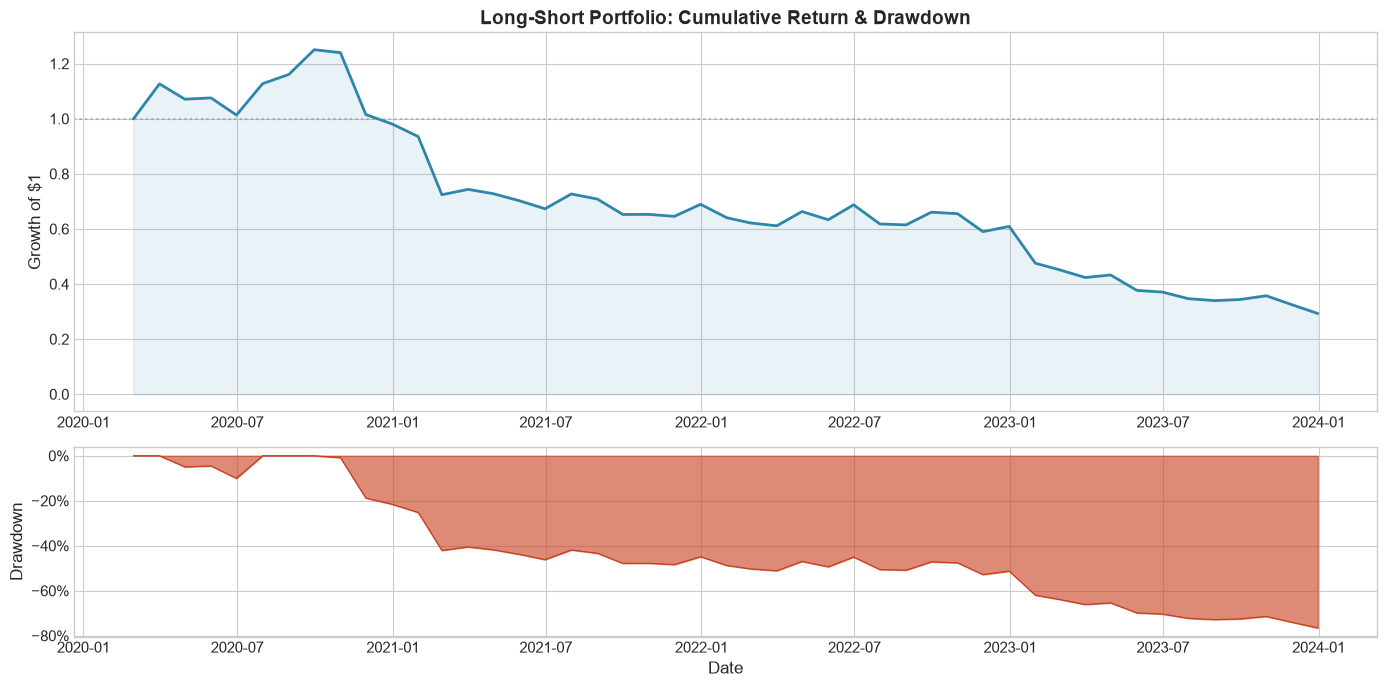

In [18]:
ls_cum = (1 + quintile_df['L/S (Q1-Q5)']).cumprod()
ls_peak = ls_cum.cummax()
ls_dd = (ls_cum - ls_peak) / ls_peak

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={'height_ratios': [2, 1]})

ax = axes[0]
ax.plot(ls_cum.index, ls_cum, color=COLORS[0], linewidth=2)
ax.fill_between(ls_cum.index, ls_cum, alpha=0.1, color=COLORS[0])
ax.set_title('Long-Short Portfolio: Cumulative Return & Drawdown', fontweight='bold')
ax.set_ylabel('Growth of $1')
ax.axhline(1.0, color='grey', linestyle=':', alpha=0.5)

ax = axes[1]
ax.fill_between(ls_dd.index, ls_dd, 0, color=COLORS[3], alpha=0.6)
ax.plot(ls_dd.index, ls_dd, color=COLORS[3], linewidth=0.8)
ax.set_ylabel('Drawdown')
ax.set_xlabel('Date')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.show()

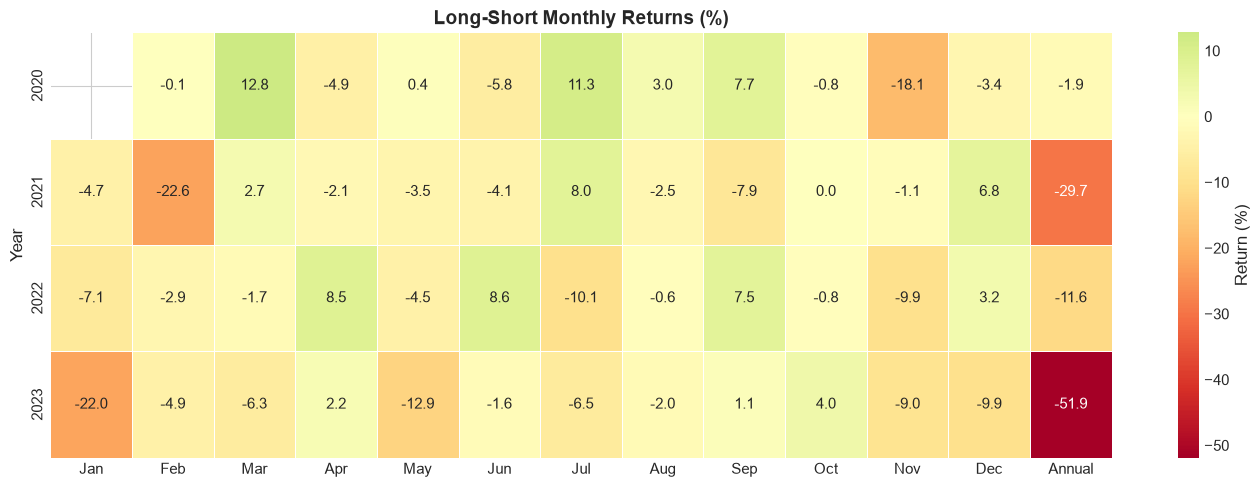

In [19]:
ls_returns = quintile_df['L/S (Q1-Q5)'].copy()
ls_returns.index = pd.to_datetime(ls_returns.index)
heatmap_data = ls_returns.groupby([ls_returns.index.year, ls_returns.index.month]).first().unstack()
heatmap_data.columns = ['Jan','Feb','Mar','Apr','May','Jun',
                         'Jul','Aug','Sep','Oct','Nov','Dec']
heatmap_data.index.name = 'Year'

heatmap_data['Annual'] = (1 + ls_returns).groupby(ls_returns.index.year).prod() - 1

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(heatmap_data * 100, annot=True, fmt='.1f', center=0,
            cmap='RdYlGn', linewidths=0.5, cbar_kws={'label': 'Return (%)'},
            ax=ax)
ax.set_title('Long-Short Monthly Returns (%)', fontweight='bold')
ax.set_ylabel('Year')
plt.tight_layout()
plt.show()

---
## 6. Fama-MacBeth Cross-Sectional Regressions

The Fama-MacBeth (1973) procedure is the standard approach for estimating **factor risk premia** from the cross-section of returns. It proceeds in two passes:

### Pass 1: Cross-Sectional Regressions (each month)

For each month $t$, run a cross-sectional regression of stock returns on lagged factor exposures:

$$r_{i,t} = \gamma_{0,t} + \gamma_{1,t}\,\text{MOM}_{i,t-1} + \gamma_{2,t}\,\text{VAL}_{i,t-1} + \gamma_{3,t}\,\text{QUAL}_{i,t-1} + \gamma_{4,t}\,\text{LVOL}_{i,t-1} + \varepsilon_{i,t}$$

This yields a **time series** of slope coefficients $\{\gamma_{k,t}\}$ for each factor $k$.

### Pass 2: Time-Series Inference

The estimated risk premium for factor $k$ is:

$$\hat{\lambda}_k = \frac{1}{T}\sum_{t=1}^T \hat{\gamma}_{k,t}$$

with the standard error corrected for serial correlation using Newey-West (1987):

$$\text{SE}(\hat{\lambda}_k) = \sqrt{\frac{1}{T^2} \sum_{j=-L}^{L} \left(1 - \frac{|j|}{L+1}\right) \hat{\Gamma}_j}$$

where $\hat{\Gamma}_j$ is the $j$-th autocovariance of $\{\hat{\gamma}_{k,t}\}$ and $L$ is the bandwidth.


In [20]:
factor_data = {}
for fname in factor_names:
    factor_data[fname] = factor_dict[fname].shift(1)

gamma_ts = {f: [] for f in ['Intercept'] + factor_names}
gamma_dates = []

for t in common_idx[1:]:
    ret_cs = ret_aligned.loc[t]
    X_dict = {f: factor_data[f].loc[t] for f in factor_names}
    X_df = pd.DataFrame(X_dict)

    combined = pd.concat([ret_cs.rename('ret'), X_df], axis=1).dropna()

    if len(combined) < 10:
        continue

    y = combined['ret'].values
    X = sm.add_constant(combined[factor_names].values)

    try:
        model = sm.OLS(y, X).fit()
        gamma_ts['Intercept'].append(model.params[0])
        for i, f in enumerate(factor_names):
            gamma_ts[f].append(model.params[i + 1])
        gamma_dates.append(t)
    except Exception:
        continue

gamma_df = pd.DataFrame(gamma_ts, index=gamma_dates)

print(f"Fama-MacBeth: {len(gamma_df)} monthly cross-sectional regressions")
print(f"Average cross-section size: ~{N_STOCKS} stocks")

Fama-MacBeth: 47 monthly cross-sectional regressions
Average cross-section size: ~32 stocks


In [21]:
nw_results = {}
for col in gamma_df.columns:
    series = gamma_df[col].values
    mean_gamma = series.mean()
    T_obs = len(series)

    nw_lags = int(np.floor(4 * (T_obs / 100) ** (2 / 9)))

    const = np.ones((T_obs, 1))
    ols_model = sm.OLS(series, const).fit(cov_type='HAC', cov_kwds={'maxlags': nw_lags})
    nw_se = ols_model.bse[0]

    t_stat = mean_gamma / nw_se if nw_se > 0 else np.nan

    nw_results[col] = {
        'Mean Coeff':    mean_gamma,
        'NW Std Err':    nw_se,
        't-stat':        t_stat,
        'p-value':       2 * (1 - stats.t.cdf(abs(t_stat), T_obs - 1)),
        'Significant':   '***' if abs(t_stat) > 2.58 else ('**' if abs(t_stat) > 1.96 else ('*' if abs(t_stat) > 1.645 else '')),
    }

fm_table = pd.DataFrame(nw_results).T
print("Fama-MacBeth Factor Premia (Newey-West corrected)")
print("=" * 70)
print(fm_table.to_string(float_format='{:.4f}'.format))
print("\nSignificance: *** p<0.01, ** p<0.05, * p<0.10")

Fama-MacBeth Factor Premia (Newey-West corrected)
          Mean Coeff NW Std Err  t-stat p-value Significant
Intercept     0.0151     0.0068  2.2085  0.0322          **
Momentum      0.0013     0.0051  0.2622  0.7943            
Value         0.0001     0.0057  0.0112  0.9911            
Quality      -0.0075     0.0033 -2.2525  0.0291          **
LowVol       -0.0017     0.0047 -0.3517  0.7266            

Significance: *** p<0.01, ** p<0.05, * p<0.10


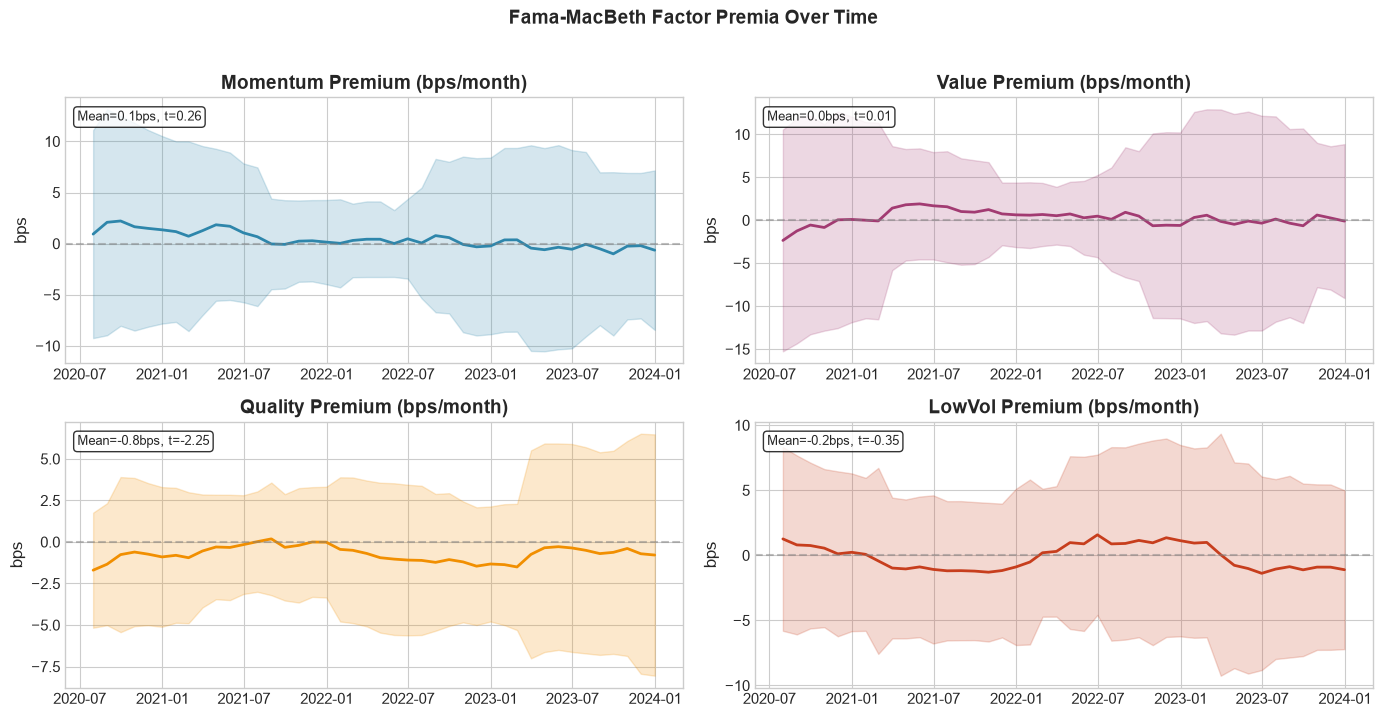

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

for idx, fname in enumerate(factor_names):
    ax = axes[idx // 2, idx % 2]
    series = gamma_df[fname]

    roll_mean = series.rolling(12, min_periods=6).mean()
    roll_std  = series.rolling(12, min_periods=6).std()

    ax.fill_between(series.index,
                    (roll_mean - 1.96 * roll_std) * 100,
                    (roll_mean + 1.96 * roll_std) * 100,
                    alpha=0.2, color=COLORS[idx])
    ax.plot(series.index, roll_mean * 100, color=COLORS[idx], linewidth=2,
            label=f'12m rolling mean')
    ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
    ax.set_title(f'{fname} Premium (bps/month)', fontweight='bold')
    ax.set_ylabel('bps')
    mean_val = series.mean() * 100
    t_val = fm_table.loc[fname, 't-stat']
    ax.text(0.02, 0.95, f'Mean={mean_val:.1f}bps, t={t_val:.2f}',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('Fama-MacBeth Factor Premia Over Time', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
## 7. Factor Decay Analysis

### Information Coefficient (IC)

The **Information Coefficient** measures the predictive power of a factor signal:

$$\text{IC}_t^{(h)} = \text{Spearman}\!\left(z_{i,t},\; r_{i,t+1:t+h}\right)$$

where $z_{i,t}$ is the factor score at time $t$ and $r_{i,t+1:t+h}$ is the forward $h$-month return.

The **IC Information Ratio** (IC_IR) captures how consistently the factor predicts:

$$\text{IC\_IR}^{(h)} = \frac{\overline{\text{IC}^{(h)}}}{\sigma(\text{IC}^{(h)})}$$

A factor "decays" when its IC drops toward zero at longer horizons, indicating that the signal loses predictive power over time.


In [23]:
horizons = [1, 2, 3, 6, 12]
ic_results = {f: {} for f in factor_names}

for fname in factor_names:
    fscores = factor_dict[fname]
    for h in horizons:
        fwd_ret = monthly_returns.shift(-h)
        if h > 1:
            fwd_ret = monthly_returns.rolling(h).apply(
                lambda x: (1 + x).prod() - 1, raw=False
            ).shift(-h)

        ics = []
        for t in common_idx:
            if t not in fscores.index or t not in fwd_ret.index:
                continue
            z_t = fscores.loc[t].dropna()
            r_fwd = fwd_ret.loc[t].dropna()
            common_stk = z_t.index.intersection(r_fwd.index)
            if len(common_stk) < 10:
                continue
            ic, _ = stats.spearmanr(z_t[common_stk], r_fwd[common_stk])
            ics.append(ic)

        ic_results[fname][h] = {
            'Mean IC':   np.mean(ics) if ics else np.nan,
            'IC Std':    np.std(ics) if ics else np.nan,
            'IC_IR':     np.mean(ics) / np.std(ics) if ics and np.std(ics) > 0 else np.nan,
            'N':         len(ics),
        }

for fname in factor_names:
    print(f"\n{fname}:")
    df_ic = pd.DataFrame(ic_results[fname]).T
    df_ic.index.name = 'Horizon (months)'
    print(df_ic.round(4).to_string())


Momentum:
                  Mean IC  IC Std   IC_IR     N
Horizon (months)                               
1                  0.0126  0.3079  0.0410  47.0
2                  0.0168  0.3300  0.0508  46.0
3                 -0.0198  0.3347 -0.0591  45.0
6                 -0.0659  0.3183 -0.2070  42.0
12                -0.2524  0.2413 -1.0460  36.0

Value:
                  Mean IC  IC Std   IC_IR     N
Horizon (months)                               
1                 -0.0258  0.3065 -0.0841  47.0
2                 -0.0187  0.3283 -0.0568  46.0
3                  0.0077  0.3251  0.0238  45.0
6                  0.0398  0.3227  0.1233  42.0
12                 0.2536  0.2450  1.0351  36.0

Quality:
                  Mean IC  IC Std   IC_IR     N
Horizon (months)                               
1                 -0.0713  0.3326 -0.2143  47.0
2                 -0.1136  0.3465 -0.3280  46.0
3                 -0.1430  0.3212 -0.4452  45.0
6                 -0.1892  0.2851 -0.6637  42.0
12         

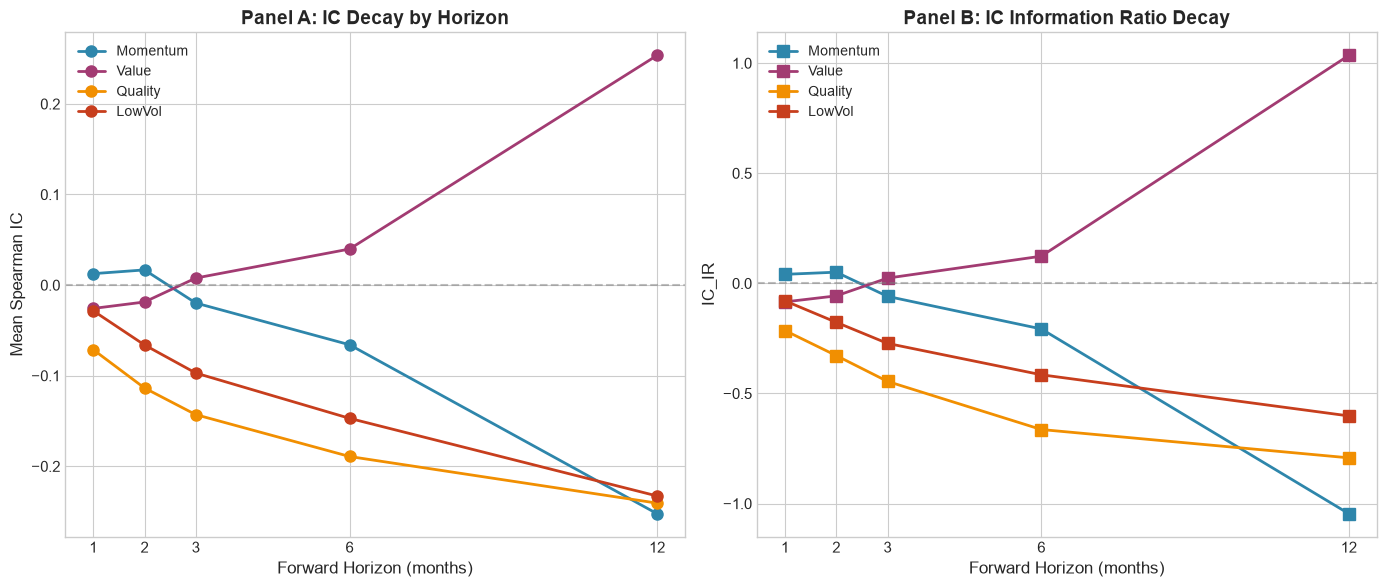

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for idx, fname in enumerate(factor_names):
    mean_ics = [ic_results[fname][h]['Mean IC'] for h in horizons]
    ax.plot(horizons, mean_ics, marker='o', color=COLORS[idx],
            linewidth=2, markersize=8, label=fname)

ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax.set_title('Panel A: IC Decay by Horizon', fontweight='bold')
ax.set_xlabel('Forward Horizon (months)')
ax.set_ylabel('Mean Spearman IC')
ax.legend()
ax.set_xticks(horizons)

ax = axes[1]
for idx, fname in enumerate(factor_names):
    ic_irs = [ic_results[fname][h]['IC_IR'] for h in horizons]
    ax.plot(horizons, ic_irs, marker='s', color=COLORS[idx],
            linewidth=2, markersize=8, label=fname)

ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax.set_title('Panel B: IC Information Ratio Decay', fontweight='bold')
ax.set_xlabel('Forward Horizon (months)')
ax.set_ylabel('IC_IR')
ax.legend()
ax.set_xticks(horizons)

plt.tight_layout()
plt.show()

---
## 8. Turnover & Transaction Cost Analysis

Portfolio turnover measures the fraction of the portfolio that is traded each rebalance:

$$\text{Turnover}_t = \frac{1}{2}\sum_{i=1}^{N} |w_{i,t}^{\text{new}} - w_{i,t}^{\text{old}}|$$

Net returns after transaction costs:

$$r_t^{\text{net}} = r_t^{\text{gross}} - c \times \text{Turnover}_t$$

where $c$ is the one-way transaction cost (in basis points).


In [25]:
q1_mask = (quintile_assignments == 1).astype(float).shift(1)

q1_weights = q1_mask.div(q1_mask.sum(axis=1), axis=0).fillna(0)

turnover = q1_weights.diff().abs().sum(axis=1) / 2
turnover = turnover.loc[quintile_df.index].dropna()

print(f"Average monthly turnover: {turnover.mean():.1%}")
print(f"Median monthly turnover:  {turnover.median():.1%}")
print(f"Annual turnover (approx): {turnover.mean() * 12:.1%}")

Average monthly turnover: 19.3%
Median monthly turnover:  14.3%
Annual turnover (approx): 231.6%


In [26]:
cost_levels_bps = [0, 10, 25, 50, 75, 100]
cost_levels = [c / 10000 for c in cost_levels_bps]

ls_turnover = turnover * 2

net_returns_dict = {}
for c_bps, c in zip(cost_levels_bps, cost_levels):
    cost_drag = ls_turnover.reindex(quintile_df.index).fillna(0) * c
    net_ret = quintile_df['L/S (Q1-Q5)'] - cost_drag
    net_returns_dict[f'{c_bps}bps'] = net_ret

net_returns_df = pd.DataFrame(net_returns_dict)

net_sharpes = {}
for col in net_returns_df.columns:
    s = net_returns_df[col]
    ann_r = s.mean() * 12
    ann_v = s.std() * np.sqrt(12)
    net_sharpes[col] = (ann_r - RISK_FREE_RATE) / ann_v if ann_v > 0 else np.nan

print("Long-Short Sharpe Ratio at Different Transaction Cost Levels:")
print("=" * 50)
for label, sr in net_sharpes.items():
    print(f"  Cost = {label:>5s} :  Sharpe = {sr:.3f}")

from scipy.interpolate import interp1d
cost_arr = np.array(cost_levels_bps)
sharpe_arr = np.array(list(net_sharpes.values()))
if sharpe_arr[0] > 0 and sharpe_arr[-1] < 0:
    f_interp = interp1d(sharpe_arr, cost_arr)
    breakeven = f_interp(0)
    print(f"\nBreak-even transaction cost: ~{breakeven:.0f} bps")
else:
    print(f"\nSharpe remains positive at all tested cost levels" if sharpe_arr[-1] > 0
          else f"\nSharpe is negative even at zero cost")

Long-Short Sharpe Ratio at Different Transaction Cost Levels:
  Cost =  0bps :  Sharpe = -1.097
  Cost = 10bps :  Sharpe = -1.114
  Cost = 25bps :  Sharpe = -1.140
  Cost = 50bps :  Sharpe = -1.183
  Cost = 75bps :  Sharpe = -1.225
  Cost = 100bps :  Sharpe = -1.268

Sharpe is negative even at zero cost


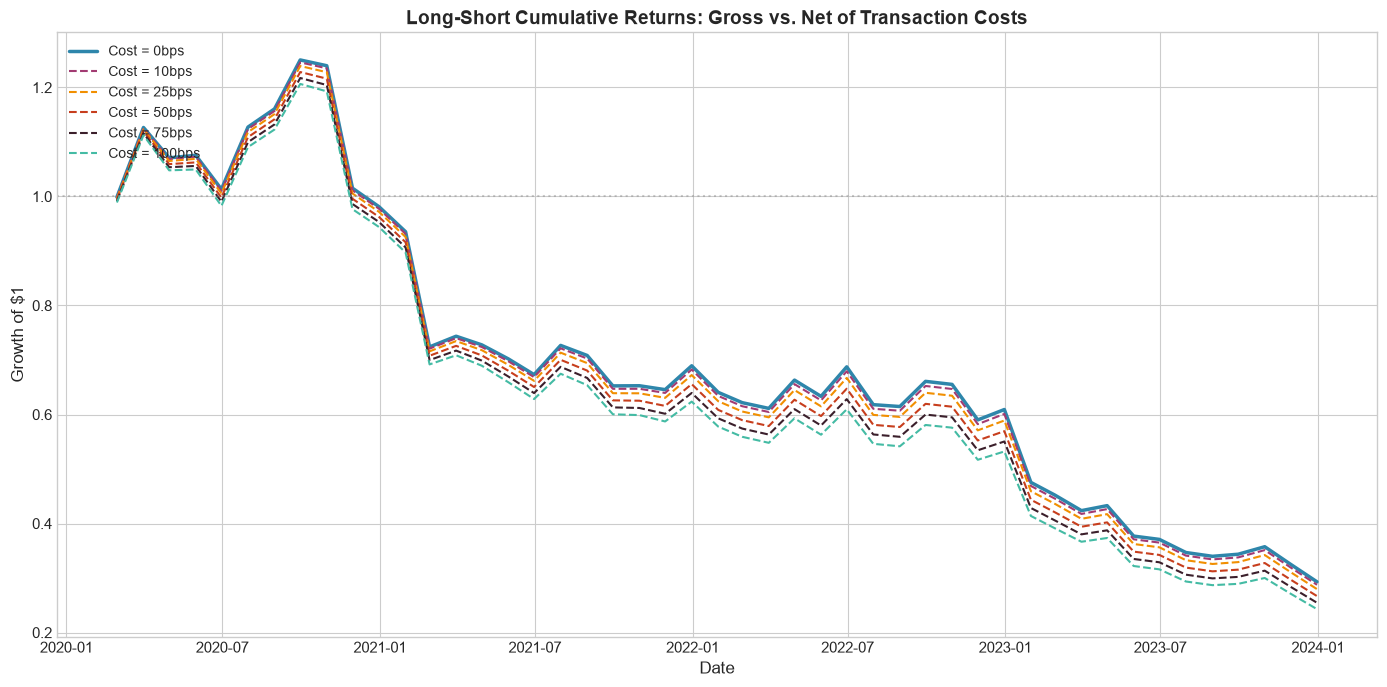

In [27]:
fig, ax = plt.subplots(figsize=(14, 7))

cum_net = (1 + net_returns_df).cumprod()
for i, col in enumerate(cum_net.columns):
    style = '-' if i == 0 else '--'
    lw = 2.5 if i == 0 else 1.5
    ax.plot(cum_net.index, cum_net[col],
            linestyle=style, linewidth=lw,
            color=COLORS[i % len(COLORS)],
            label=f'Cost = {col}')

ax.set_title('Long-Short Cumulative Returns: Gross vs. Net of Transaction Costs',
             fontweight='bold', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Growth of $1')
ax.legend(loc='upper left', framealpha=0.9)
ax.axhline(1.0, color='grey', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

---
## 9. Out-of-Sample Validation

A critical test of any factor strategy is its performance **out-of-sample**. The data is split as follows:

- **In-Sample (IS):** First 60% of months — used to optimize factor weights
- **Out-of-Sample (OOS):** Last 40% of months — used to evaluate true performance

Factor weights are optimized in-sample by maximizing the Sharpe ratio of the resulting long-short portfolio, then a test evaluates whether these optimized weights improve OOS performance relative to equal weights.


In [28]:
split_idx = int(len(common_idx) * 0.6)
is_dates = common_idx[:split_idx]
oos_dates = common_idx[split_idx:]

print(f"In-Sample  : {is_dates[0].strftime('%Y-%m')} to {is_dates[-1].strftime('%Y-%m')} ({len(is_dates)} months)")
print(f"Out-of-Sample: {oos_dates[0].strftime('%Y-%m')} to {oos_dates[-1].strftime('%Y-%m')} ({len(oos_dates)} months)")

In-Sample  : 2020-01 to 2022-04 (28 months)
Out-of-Sample: 2022-05 to 2023-12 (20 months)


In [29]:
def build_ls_returns(weights, factor_dict, ret_aligned, dates):
    '''Build long-short returns for given factor weights and dates.'''
    w = np.array(weights)
    w = w / np.sum(np.abs(w))

    composite_w = sum(w[i] * factor_dict[f].loc[dates]
                      for i, f in enumerate(factor_names))

    qa = composite_w.apply(
        lambda row: pd.qcut(row.dropna(), 5, labels=[5, 4, 3, 2, 1]).reindex(row.index),
        axis=1
    )
    q1_mask = (qa == 1).astype(float).replace(0, np.nan).shift(1)
    q5_mask = (qa == 5).astype(float).replace(0, np.nan).shift(1)

    r = ret_aligned.loc[dates]
    q1_ret = (r * q1_mask).sum(axis=1) / q1_mask.sum(axis=1)
    q5_ret = (r * q5_mask).sum(axis=1) / q5_mask.sum(axis=1)
    ls_ret = (q1_ret - q5_ret).dropna()
    return ls_ret

def neg_sharpe(weights, factor_dict, ret_aligned, dates):
    '''Negative Sharpe ratio for minimization.'''
    ls_ret = build_ls_returns(weights, factor_dict, ret_aligned, dates)
    if len(ls_ret) < 12:
        return 10.0
    ann_r = ls_ret.mean() * 12
    ann_v = ls_ret.std() * np.sqrt(12)
    if ann_v < 1e-8:
        return 10.0
    return -(ann_r - RISK_FREE_RATE) / ann_v

initial_w = [0.25, 0.25, 0.25, 0.25]
bounds = [(0, 1)] * 4

result = minimize(
    neg_sharpe, initial_w,
    args=(factor_dict, ret_aligned, is_dates),
    method='Nelder-Mead',
    options={'maxiter': 500, 'xatol': 1e-4}
)

opt_weights = result.x / np.sum(result.x)
print("Optimized Factor Weights (In-Sample):")
for fname, w in zip(factor_names, opt_weights):
    print(f"  {fname:12s}: {w:.3f}")
print(f"\nIS Sharpe (optimized): {-result.fun:.3f}")

Optimized Factor Weights (In-Sample):
  Momentum    : 0.228
  Value       : 0.284
  Quality     : 0.244
  LowVol      : 0.243

IS Sharpe (optimized): -0.295


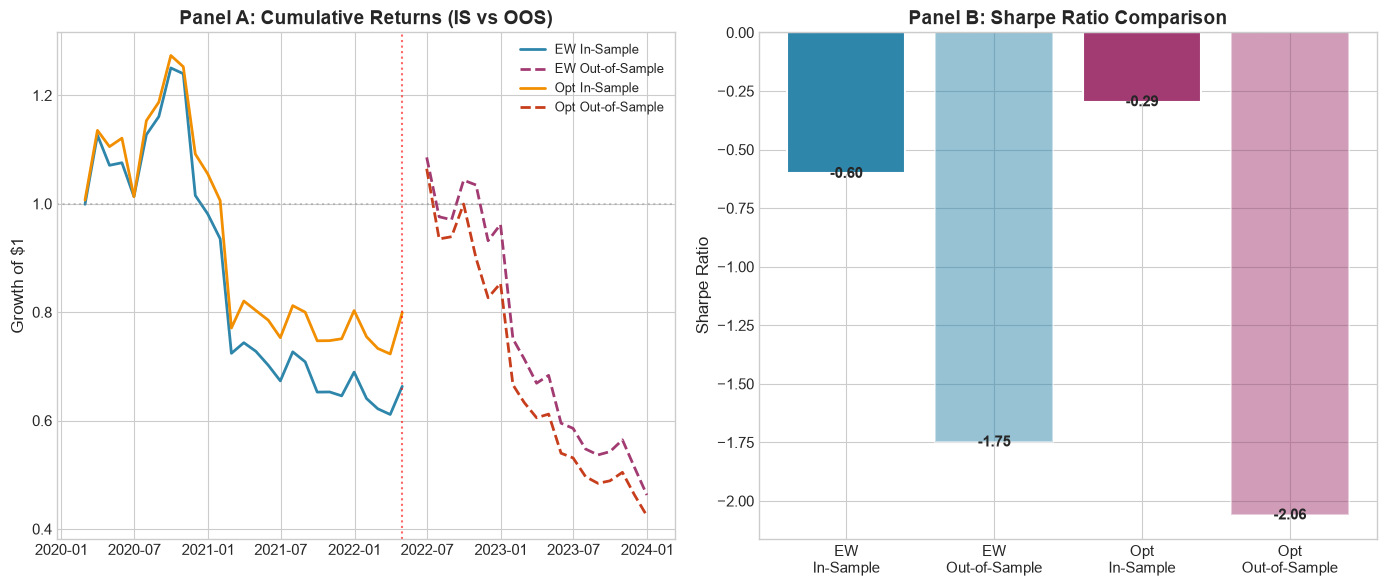


Detailed Comparison:


,Ann. Return,Ann. Vol,Sharpe,Sortino,Max DD,Calmar,Win Rate,Skewness,Kurtosis
EW (IS),-14.35%,27.21%,-0.60,-0.78,-51.12%,-0.28,37.0%,-0.66,1.51
EW (OOS),-44.17%,26.42%,-1.75,-2.24,-57.38%,-0.77,31.6%,-0.48,0.33
Opt (IS),-6.12%,27.51%,-0.29,-0.40,-43.24%,-0.14,44.4%,-0.55,1.60
Opt (OOS),-49.74%,25.13%,-2.06,-2.75,-60.15%,-0.83,36.8%,-0.56,0.44


In [30]:
ew_is = build_ls_returns([0.25]*4, factor_dict, ret_aligned, is_dates)
ew_oos = build_ls_returns([0.25]*4, factor_dict, ret_aligned, oos_dates)

opt_is = build_ls_returns(opt_weights, factor_dict, ret_aligned, is_dates)
opt_oos = build_ls_returns(opt_weights, factor_dict, ret_aligned, oos_dates)

comparison = pd.DataFrame({
    'EW (IS)':  compute_metrics(ew_is),
    'EW (OOS)': compute_metrics(ew_oos),
    'Opt (IS)': compute_metrics(opt_is),
    'Opt (OOS)': compute_metrics(opt_oos),
}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for i, (label, ret_series) in enumerate([
    ('EW In-Sample', ew_is), ('EW Out-of-Sample', ew_oos),
    ('Opt In-Sample', opt_is), ('Opt Out-of-Sample', opt_oos)
]):
    cum = (1 + ret_series).cumprod()
    style = '-' if 'In-Sample' in label else '--'
    ax.plot(cum.index, cum, label=label, color=COLORS[i],
            linestyle=style, linewidth=2)

ax.axhline(1.0, color='grey', linestyle=':', alpha=0.4)
ax.set_title('Panel A: Cumulative Returns (IS vs OOS)', fontweight='bold')
ax.set_ylabel('Growth of $1')
ax.legend(fontsize=9)

split_date = is_dates[-1]
ax.axvline(split_date, color='red', linestyle=':', alpha=0.6, linewidth=1.5)

ax = axes[1]
labels = ['EW\nIn-Sample', 'EW\nOut-of-Sample', 'Opt\nIn-Sample', 'Opt\nOut-of-Sample']
sharpes = [comparison.loc[c, 'Sharpe'] for c in comparison.index]
bar_colors = [COLORS[0], COLORS[0], COLORS[1], COLORS[1]]
alphas = [1.0, 0.5, 1.0, 0.5]

bars = ax.bar(labels, sharpes, color=bar_colors, edgecolor='white', linewidth=1.5)
for bar, a in zip(bars, alphas):
    bar.set_alpha(a)

ax.set_title('Panel B: Sharpe Ratio Comparison', fontweight='bold')
ax.set_ylabel('Sharpe Ratio')
ax.axhline(0, color='grey', linestyle='--', alpha=0.5)

for i, (v, lbl) in enumerate(zip(sharpes, labels)):
    ax.text(i, v + 0.02 * np.sign(v), f'{v:.2f}', ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

print("\nDetailed Comparison:")
comparison_styled = comparison.style.format({
    'Ann. Return': '{:.2%}', 'Ann. Vol': '{:.2%}', 'Sharpe': '{:.2f}',
    'Sortino': '{:.2f}', 'Max DD': '{:.2%}', 'Calmar': '{:.2f}',
    'Win Rate': '{:.1%}', 'Skewness': '{:.2f}', 'Kurtosis': '{:.2f}',
})
comparison_styled

---
## 10. Rolling Analysis

Rolling metrics reveal the **time-varying nature** of factor performance. The analysis computes 12-month rolling windows for key statistics to assess regime dependence and stationarity.


In [31]:
window = 12
ls_ret = quintile_df['L/S (Q1-Q5)']
bench_ret = quintile_df['Benchmark']

rolling_sharpe = (ls_ret.rolling(window).mean() * 12 - RISK_FREE_RATE) / \
                 (ls_ret.rolling(window).std() * np.sqrt(12))

rolling_alpha = pd.Series(index=ls_ret.index, dtype=float)
rolling_beta  = pd.Series(index=ls_ret.index, dtype=float)

for i in range(window, len(ls_ret)):
    y = ls_ret.iloc[i - window:i].values
    x = bench_ret.iloc[i - window:i].values
    X = sm.add_constant(x)
    try:
        res = sm.OLS(y, X).fit()
        rolling_alpha.iloc[i] = res.params[0] * 12
        rolling_beta.iloc[i]  = res.params[1]
    except Exception:
        pass

rolling_vol = ls_ret.rolling(window).std() * np.sqrt(12)

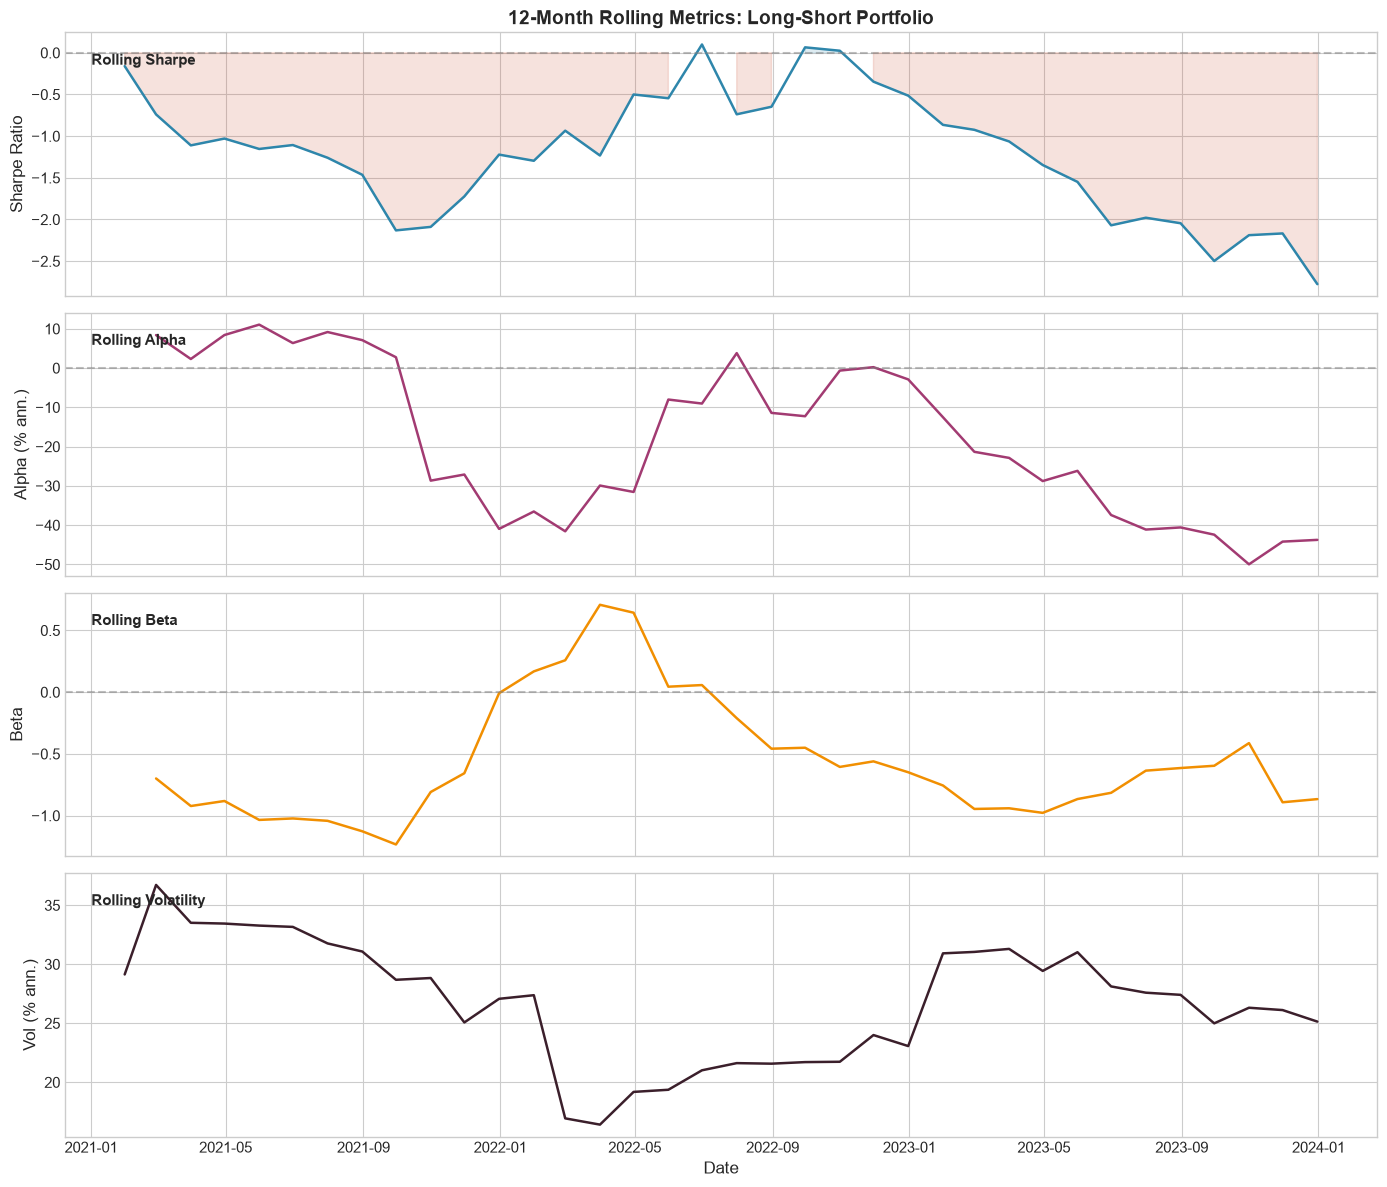

In [32]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

ax = axes[0]
ax.plot(rolling_sharpe.index, rolling_sharpe, color=COLORS[0], linewidth=1.8)
ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax.fill_between(rolling_sharpe.index, rolling_sharpe, 0,
                where=rolling_sharpe > 0, alpha=0.15, color=COLORS[0])
ax.fill_between(rolling_sharpe.index, rolling_sharpe, 0,
                where=rolling_sharpe <= 0, alpha=0.15, color=COLORS[3])
ax.set_title(f'{window}-Month Rolling Metrics: Long-Short Portfolio', fontweight='bold', fontsize=14)
ax.set_ylabel('Sharpe Ratio')
ax.text(0.02, 0.92, 'Rolling Sharpe', transform=ax.transAxes,
        fontweight='bold', fontsize=11, verticalalignment='top')

ax = axes[1]
ax.plot(rolling_alpha.index, rolling_alpha * 100, color=COLORS[1], linewidth=1.8)
ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax.set_ylabel('Alpha (% ann.)')
ax.text(0.02, 0.92, 'Rolling Alpha', transform=ax.transAxes,
        fontweight='bold', fontsize=11, verticalalignment='top')

ax = axes[2]
ax.plot(rolling_beta.index, rolling_beta, color=COLORS[2], linewidth=1.8)
ax.axhline(0, color='grey', linestyle='--', alpha=0.5)
ax.set_ylabel('Beta')
ax.text(0.02, 0.92, 'Rolling Beta', transform=ax.transAxes,
        fontweight='bold', fontsize=11, verticalalignment='top')

ax = axes[3]
ax.plot(rolling_vol.index, rolling_vol * 100, color=COLORS[4], linewidth=1.8)
ax.set_ylabel('Vol (% ann.)')
ax.set_xlabel('Date')
ax.text(0.02, 0.92, 'Rolling Volatility', transform=ax.transAxes,
        fontweight='bold', fontsize=11, verticalalignment='top')

plt.tight_layout()
plt.show()

---
## 11. Conclusions

**Bottom line:** Over 2020–2023, the equal-weight composite factor strategy **failed**. The long-short portfolio (Q1 − Q5) lost **27.3% per year** (Sharpe **−1.10**) and turned \$1 into **\$0.29**. The highest-scoring stocks earned **7.4%/yr**, versus **34.7%/yr** for the lowest-scoring stocks and **17.2%/yr** for the equal-weight benchmark.

### Key Findings

**1. The composite signal ranked stocks in the wrong order.**

| Portfolio | Ann. Return | Ann. Vol | Sharpe | Max DD |
|:--|--:|--:|--:|--:|
| Q1 (best score) | 7.4% | 16.2% | 0.33 | −18.0% |
| Q2 | 14.9% | 19.6% | 0.66 | −14.7% |
| Q3 | 12.0% | 23.4% | 0.43 | −19.1% |
| Q4 | 15.9% | 24.3% | 0.57 | −20.4% |
| Q5 (worst score) | 34.7% | 30.6% | 1.07 | −26.6% |
| L/S (Q1 − Q5) | −27.3% | 26.7% | −1.10 | −76.6% |
| Benchmark (EW) | 17.2% | 20.1% | 0.76 | −17.8% |

- Returns rise from Q1 to Q5, the opposite of what the strategy assumes. The pattern is not strictly monotonic (Q3 < Q2), and most of the gap comes from Q5.
- The L/S portfolio lost money in **every calendar year**: 2020 −1.9%, 2021 −29.7%, 2022 −11.6%, 2023 −51.9%. Only 16 of 47 months were positive.
- Its two best months were risk-off months: March 2020 (+12.8%) and June 2022 (+8.6%). Its worst were risk-on rallies: February 2021 (−22.6%), January 2023 (−22.0%) and November 2020 (−18.1%).
- The 1-month Spearman IC of the composite averaged **−0.053** (IC_IR −0.16). It was positive in only 36% of months.

**2. In practice, the composite is a low-volatility / defensive-sector bet.**
- Momentum and Value have an average cross-sectional correlation of **−0.95**, because the value proxy (−12-month return) is nearly the inverse of 12-1 momentum. When summed, they largely cancel: the standard deviation of Mom + Val is 0.42, versus about 1.0 for each factor alone. Together they add almost no information to the composite.
- Quality and LowVol are both inverse-volatility measures and have a correlation of **0.74**. As a result, the composite is driven mainly by low volatility. The four factors are **not** four distinct sources of return.
- Sector mix:
  - **Q1** was 52% Consumer Staples, 27% Healthcare and 13% Utilities/REITs, with only 3% Technology. Its most frequent holdings were PG, PEP, JNJ, WMT and KO.
  - **Q5** was 28% Technology, 24% Industrials and 23% Energy. Its most frequent holdings were BA, COP, NVDA, GE and XOM.
- The L/S portfolio has a **beta of −0.68** to the benchmark (t = −3.96, R² = 0.26). After adjusting for this beta, annualized alpha is −15.6% but **not significant** (t = −1.29). Most of the loss comes from being short the market in a rising market (benchmark +81% cumulative), not from security selection.
- The defensive tilt also failed to protect in 2022: Q1 returned −6.5%, versus −5.9% for the benchmark and −1.1% for Q5, because Energy names in Q5 (COP, XOM) rallied.

**3. Single-factor results: no factor earned a positive premium.**

| Factor (Q1 − Q5) | Ann. Return | Sharpe |
|:--|--:|--:|
| Momentum | +0.5% | −0.05 |
| Value (price proxy) | −6.9% | −0.30 |
| Quality | −34.1% | −1.37 |
| LowVol | −17.8% | −0.67 |

Quality and LowVol, which drive the composite, were also the worst-performing factors.

**4. Fama-MacBeth regressions confirm these results.**
- **Quality** is the only significant factor premium, and its sign is **negative**: −0.75% per month per 1σ of exposure (Newey-West t = −2.25, p = 0.03).
- Momentum (t = 0.26), Value (t = 0.01) and LowVol (t = −0.35) are statistically indistinguishable from zero.
- The intercept is +1.51% per month (t = 2.21), which reflects the strong overall market rather than any factor.
- The Momentum premium fell sharply in March 2020 (−6.1%) and April 2020 (−4.6%), then rebounded in May (+5.3%). Its 2020 average was still positive (+1.35%/month).
- LowVol earned a positive premium only in 2022 (+1.13%/month). It was negative in 2021 (−0.89%) and 2023 (−1.10%).

**5. IC by horizon: the negative signal gets stronger at longer horizons.**
- Quality IC goes from −0.07 (1 month) to −0.24 (12 months), and LowVol IC from −0.03 to −0.23.
- Momentum IC is about zero at 1–3 months and reaches −0.25 at 12 months, which suggests long-horizon reversal.
- Value IC mirrors Momentum, reaching +0.25 at 12 months, because it is close to the same signal with the sign flipped.
- None of the factors shows the expected pattern of a positive IC that fades with horizon.

**6. Transaction costs are not the binding constraint.**
- Top-quintile turnover averages 19.3% per month (median 14.3%), or about 232% per year.
- The L/S Sharpe goes from −1.10 at 0 bps to −1.27 at 100 bps. The strategy loses money before costs, so there is no break-even cost.

**7. Out-of-sample: worse, and optimization did not help.**
- In-sample period: Jan 2020 – Apr 2022 (28 months). Out-of-sample period: May 2022 – Dec 2023 (20 months).
- The optimized weights (Mom 0.23, Val 0.28, Qual 0.24, LowVol 0.24) are close to equal weight.

| | In-Sample Sharpe | Out-of-Sample Sharpe |
|:--|--:|--:|
| Equal weight | −0.60 | −1.75 |
| Optimized | −0.30 | −2.06 |

- Optimization improved the in-sample Sharpe but **worsened** the out-of-sample Sharpe. This is overfitting to noise in a 27-month sample.

**8. Rolling 12-month analysis: consistently negative.**
- The rolling Sharpe was positive in only **8%** of windows. It peaked at 0.10 in June 2022 (the rate-hike drawdown) and ended at −2.78 in December 2023.
- Rolling beta was negative 83% of the time, ranging from −1.23 (September 2021) to +0.71 (March 2022). The L/S portfolio is not market-neutral.
- Rolling volatility ranged from 16.4% to 36.7%.

### What the Results Mean
In the 2020–2023 period, a long-defensive / short-cyclical portfolio was the wrong position. Mega-cap tech (NVDA, META, AMZN), energy (2021–2022) and the recovery trade (BA, GE) drove returns. The poor result reflects the market regime and the sector tilt, not a failed implementation. However, the notebook provides **no evidence** that this composite earns a premium in this universe.

### Limitations
- **Small sample:** 32 stocks (about 6–7 per quintile) and 47 monthly return observations. The L/S mean has a t-stat of only −2.02, so a single regime can dominate the results.
- **Survivorship and look-ahead bias:** The universe consists of today's large-cap winners (e.g., NVDA, META), picked with hindsight. This favors high-volatility stocks and penalizes the low-volatility leg.
- **Redundant factor definitions:** Value is defined as −Momentum, and Quality and LowVol are both inverse volatility. In effect, the composite is closer to one or two signals than four.
- **No sector or beta neutralization:** The L/S result is mostly a sector bet and a negative-beta bet.
- **Constant 2% risk-free rate:** Actual T-bill yields ranged from about 0% (2020–2021) to above 5% (2023).
- **Optimizer bounds not enforced:** `bounds` is defined but never passed to `minimize`.

### Next Steps
- Replace the price-based value proxy with fundamental data (B/M, E/P), and quality with profitability measures (ROE, gross profitability).
- Make factors sector-neutral and the L/S portfolio beta-neutral, to separate factor returns from sector and market exposure.
- Expand to a point-in-time universe of 500 or more stocks, and test over a longer history covering several market regimes.
- Use a rolling or expanding-window validation in place of a single 60/40 split.